# 📊 DeepNT+ : 5-Seed Clean Benchmark Suite
### Robust Multi-Seed Academic Evaluation Across 3 Datasets
**Thesis:** *Hybrid Path-Centric GNN Approach for Robust and Dynamic Network Tomography (DeepNT+)*  
**Protocol:** Clean 5-Seed Benchmark (`seeds = 0, 1, 2, 3, 4`) across:
1. **`run_02`**: Balanced 15-graph IPv4 dataset (~400 nodes/graph)
2. **`run_03`**: Compressed 5-graph IPv4 dataset (1,096–1,372 nodes/graph)
3. **`run_ipv6`**: Globally reconstructed 5-graph IPv6 CAIDA Ark dataset (1,765–3,039 nodes/graph)
**Techniques Included:** Laplace NLL Loss, Coverage-Aware Residual Gate ($b_g = -2.0$), Dynamic Context Rate Warm Start, CosineAnnealingLR.


In [1]:
# ==============================================================================
# Cell 1: Environment Setup & Drive Auto-Mount
# ==============================================================================
import sys
import os
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    print(" Running in Google Colab environment. Drive mounted successfully.")
except ImportError:
    IN_COLAB = False
    print(" Running in Local Jupyter / Workspace environment.")

if IN_COLAB:
    BASE_DIR = Path("/content/drive/My Drive/Thesis")
else:
    BASE_DIR = Path("C:/Users/KINGDOM/Desktop/Thesis")

COLAB_DIR = BASE_DIR / "colab"
OUTPUT_DIR = BASE_DIR / "DeepNT_Output"

# Add colab directory to python path
candidates = [COLAB_DIR, Path.cwd(), Path.cwd().parent]
for c in candidates:
    if (c / "deepnt_plus" / "__init__.py").exists():
        sys.path.insert(0, str(c))
        print(f" Found deepnt_plus package at: {c}")
        break

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print(f" PyTorch: {torch.__version__} | CUDA Available: {torch.cuda.is_available()}")


 Running in Local Jupyter / Workspace environment.
 Found deepnt_plus package at: C:\Users\KINGDOM\Desktop\Thesis\colab
 PyTorch: 2.14.0+cpu | CUDA Available: False


In [2]:
# ==============================================================================
# Cell 2: Benchmark Configuration & Dataset Setup
# ==============================================================================
DATASETS = {
    'run_02': OUTPUT_DIR / 'data' / 'processed_15graphs_backup',
    'run_03': OUTPUT_DIR / 'data' / 'processed',
    'run_ipv6': OUTPUT_DIR / 'reconstructed_dataset' / 'ipv6',
}

OUT_BASE = OUTPUT_DIR / 'experiments' / 'deepnt' / 'benchmark_5seeds'
OUT_BASE.mkdir(parents=True, exist_ok=True)

SEEDS = [0, 1, 2, 3, 4]
EPOCHS = 40  # 40 epochs optimal with CosineAnnealingLR + patience 15
LOSS_TYPE = 'laplace'
USE_COSINE_LR = True
RESIDUAL_REG = 0.05

NEURAL_MODELS = {
    'DeepNT+ (full, improved)': dict(gnn_kind='split', tomography=True, convex=True, temporal=True, uncertainty=True, causal=True),
    'DeepNT (static, causal)': dict(gnn_kind='split', tomography=True, convex=True, temporal=False, uncertainty=True, causal=True),
    'DeepNT (static, non-causal)': dict(gnn_kind='split', tomography=True, convex=True, temporal=False, uncertainty=True, causal=False),
    'GAT': dict(gnn_kind='gat', tomography=False, convex=False, temporal=False, uncertainty=False, causal=False),
    'GraphSAGE': dict(gnn_kind='sage', tomography=False, convex=False, temporal=False, uncertainty=False, causal=False),
}

print(f" Datasets to benchmark: {list(DATASETS.keys())}")
print(f" Seeds: {SEEDS} | Epochs: {EPOCHS} | Output: {OUT_BASE}")


 Datasets to benchmark: ['run_02', 'run_03', 'run_ipv6']
 Seeds: [0, 1, 2, 3, 4] | Epochs: 40 | Output: C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\experiments\deepnt\benchmark_5seeds


In [3]:
# ==============================================================================
# Cell 3: Run Benchmark Suite Across Datasets & Seeds
# ==============================================================================
import time
from deepnt_plus.data import load_dataset, NODE_FEATURES
from deepnt_plus.model import DeepNTPlus, ModelConfig
from deepnt_plus.train import TrainConfig, train_model, evaluate, score
from deepnt_plus.baselines import run_structural_baselines, run_convex_baseline

master_summary = []

for dname, dpath in DATASETS.items():
    print(f"\n=======================================================")
    print(f"BENCHMARKING DATASET: {dname}")
    print(f"=======================================================")
    
    out_dir = OUT_BASE / dname
    out_dir.mkdir(parents=True, exist_ok=True)
    pred_csv = out_dir / 'predictions_all.csv'
    metrics_csv = out_dir / 'metrics_summary.csv'

    graphs, norm = load_dataset(dpath)
    print(f"Loaded {len(graphs)} graphs from {dpath}")

    all_preds = []
    existing_df = pd.DataFrame()
    if pred_csv.exists():
        existing_df = pd.read_csv(pred_csv)
        all_preds.append(existing_df)
        print(f"Loaded {len(existing_df)} existing predictions from disk.")

    existing_models = set(existing_df['model'].unique()) if not existing_df.empty else set()

    # 1. Classical Baselines
    if 'Median' not in existing_models:
        print("\n--- Running Classical Baselines (Median, Hop-count, Warm-Start Convex, RF, MLP) ---")
        for seed in SEEDS:
            struct_df = run_structural_baselines(graphs, seed=seed)
            struct_df['seed'] = seed
            all_preds.append(struct_df)

        convex_df = run_convex_baseline(graphs, norm, warm_start=True)
        for seed in SEEDS:
            c_seed = convex_df.copy()
            c_seed['seed'] = seed
            all_preds.append(c_seed)
    else:
        print("Classical baselines already cached.")

    # 2. Neural Models across 5 Seeds
    for mname, mparams in NEURAL_MODELS.items():
        print(f"\n--- Model: {mname} ---")
        for seed in SEEDS:
            if not existing_df.empty and len(existing_df[(existing_df['model'] == mname) & (existing_df['seed'] == seed)]) > 0:
                print(f"  Seed {seed} already computed, skipping.")
                continue

            t0 = time.time()
            is_causal = mparams.get('causal', False) if dname != 'run_ipv6' else False
            model_params = {k: v for k, v in mparams.items() if k != 'causal'}
            mcfg = ModelConfig(node_dim=len(NODE_FEATURES), **model_params)
            tcfg = TrainConfig(epochs=EPOCHS, patience=15, causal=is_causal, loss_type=LOSS_TYPE, use_cosine_lr=USE_COSINE_LR, residual_reg_weight=RESIDUAL_REG)

            torch.manual_seed(seed)
            np.random.seed(seed)
            model = DeepNTPlus(mcfg, norm)

            hist = train_model(model, graphs, tcfg, seed=seed)
            frames = []
            for split in ('val', 'test'):
                f = evaluate(model, graphs, split, tcfg, mc=10 if mcfg.uncertainty else 0)
                f['model'] = mname
                f['seed'] = seed
                frames.append(f)
            
            res_df = pd.concat(frames, ignore_index=True)
            all_preds.append(res_df)
            
            combined_so_far = pd.concat(all_preds, ignore_index=True)
            combined_so_far.to_csv(pred_csv, index=False)
            
            test_sc = score(res_df[res_df['split'] == 'test'])
            val_sc = score(res_df[res_df['split'] == 'val'])
            print(f"  Seed {seed} ({time.time()-t0:.1f}s) | Val MAE: {val_sc['MAE']:.2f} ms | Test MAE: {test_sc['MAE']:.2f} ms | Test RMSE: {test_sc['RMSE']:.2f} ms | R2: {test_sc['R2']:.3f}")

    combined = pd.concat(all_preds, ignore_index=True)
    if {'model', 'split', 'seed', 'graph_id', 'path_id'}.issubset(combined.columns):
        combined = combined.drop_duplicates(subset=['model', 'split', 'seed', 'graph_id', 'path_id'])
    combined.to_csv(pred_csv, index=False)

    # Compute metrics per seed
    rows = []
    for (m, sp, sd), grp in combined.groupby(['model', 'split', 'seed']):
        sc = score(grp)
        sc.update({'dataset': dname, 'model': m, 'split': sp, 'seed': sd})
        rows.append(sc)
    
    per_seed_metrics = pd.DataFrame(rows)
    per_seed_metrics.to_csv(out_dir / 'metrics_per_seed.csv', index=False)

    test_metrics = per_seed_metrics[per_seed_metrics['split'] == 'test']
    num_cols = [c for c in ['MAE', 'RMSE', 'R2', 'coverage_90', 'ECE_reg', 'NLL'] if c in test_metrics.columns]
    agg_dict = {c: ['mean', 'std'] for c in num_cols}
    agg = test_metrics.groupby(['dataset', 'model']).agg(agg_dict).reset_index()
    agg.columns = ['_'.join(c).strip('_') for c in agg.columns]
    agg = agg.sort_values('MAE_mean').reset_index(drop=True)
    agg.to_csv(metrics_csv, index=False)
    master_summary.append(agg)

master_df = pd.concat(master_summary, ignore_index=True)
master_df.to_csv(OUT_BASE / 'master_summary_5seeds.csv', index=False)
print(f"\n Benchmark Complete! Master table saved to: {OUT_BASE / 'master_summary_5seeds.csv'}")



BENCHMARKING DATASET: run_02
Loaded 15 graphs from C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\data\processed_15graphs_backup
Loaded 12050 existing predictions from disk.
Classical baselines already cached.

--- Model: DeepNT+ (full, improved) ---
  Seed 0 (39.8s) | Val MAE: 35.74 ms | Test MAE: 46.66 ms | Test RMSE: 60.78 ms | R2: 0.579
  Seed 1 (42.2s) | Val MAE: 31.24 ms | Test MAE: 46.87 ms | Test RMSE: 62.69 ms | R2: 0.552
  Seed 2 (25.8s) | Val MAE: 32.70 ms | Test MAE: 49.22 ms | Test RMSE: 62.76 ms | R2: 0.551
  Seed 3 (25.8s) | Val MAE: 35.10 ms | Test MAE: 50.87 ms | Test RMSE: 61.67 ms | R2: 0.566
  Seed 4 (35.0s) | Val MAE: 34.03 ms | Test MAE: 50.03 ms | Test RMSE: 63.04 ms | R2: 0.547

--- Model: DeepNT (static, causal) ---
  Seed 0 already computed, skipping.
  Seed 1 already computed, skipping.
  Seed 2 already computed, skipping.
  Seed 3 already computed, skipping.
  Seed 4 already computed, skipping.

--- Model: GAT ---
  Seed 0 already computed, skipping.
  Seed 

In [4]:
# ==============================================================================
# Cell 4: Display Master Summary Table
# ==============================================================================
for dname in DATASETS:
    d_csv = OUT_BASE / dname / 'metrics_summary.csv'
    if d_csv.exists():
        df = pd.read_csv(d_csv)
        print(f"\n==========================================================================================")
        print(f"                       5-SEED BENCHMARK RESULTS: {dname.upper()}")
        print(f"==========================================================================================")
        for _, r in df.iterrows():
            cov_str = f" | Cov90: {r['coverage_90_mean']:.3f} ± {r['coverage_90_std']:.3f}" if 'coverage_90_mean' in r and pd.notna(r['coverage_90_mean']) else ""
            ece_str = f" | ECE: {r['ECE_reg_mean']:.3f} ± {r['ECE_reg_std']:.3f}" if 'ECE_reg_mean' in r and pd.notna(r['ECE_reg_mean']) else ""
            print(f"  {r['model']:30s} | MAE: {r['MAE_mean']:6.2f} ± {r['MAE_std']:4.2f} ms | RMSE: {r['RMSE_mean']:6.2f} ± {r['RMSE_std']:4.2f} ms | R2: {r['R2_mean']:6.3f} ± {r['R2_std']:5.3f}{cov_str}{ece_str}")
        print(f"==========================================================================================")



                       5-SEED BENCHMARK RESULTS: RUN_02
  Convex tomography (classical)  | MAE:  48.37 ± 0.00 ms | RMSE:  61.27 ± 0.00 ms | R2:  0.572 ± 0.000
  DeepNT+ (full)                 | MAE:  48.71 ± 1.91 ms | RMSE:  62.15 ± 0.92 ms | R2:  0.559 ± 0.013 | Cov90: 0.815 ± 0.083 | ECE: 0.081 ± 0.069
  DeepNT+ (full, improved)       | MAE:  48.73 ± 1.89 ms | RMSE:  62.19 ± 0.94 ms | R2:  0.559 ± 0.013 | Cov90: 0.812 ± 0.079 | ECE: 0.080 ± 0.069
  DeepNT (static, causal)        | MAE:  48.74 ± 1.89 ms | RMSE:  62.41 ± 1.20 ms | R2:  0.556 ± 0.017 | Cov90: 0.814 ± 0.028 | ECE: 0.075 ± 0.033
  GAT                            | MAE:  54.33 ± 6.15 ms | RMSE:  70.45 ± 4.50 ms | R2:  0.432 ± 0.075
  Random forest                  | MAE:  63.65 ± 0.82 ms | RMSE:  75.72 ± 0.97 ms | R2:  0.346 ± 0.017
  GraphSAGE                      | MAE:  68.95 ± 10.73 ms | RMSE:  80.22 ± 10.46 ms | R2:  0.256 ± 0.186
  Median                         | MAE:  78.16 ± 0.00 ms | RMSE:  93.67 ± 0.00 ms | R2: 

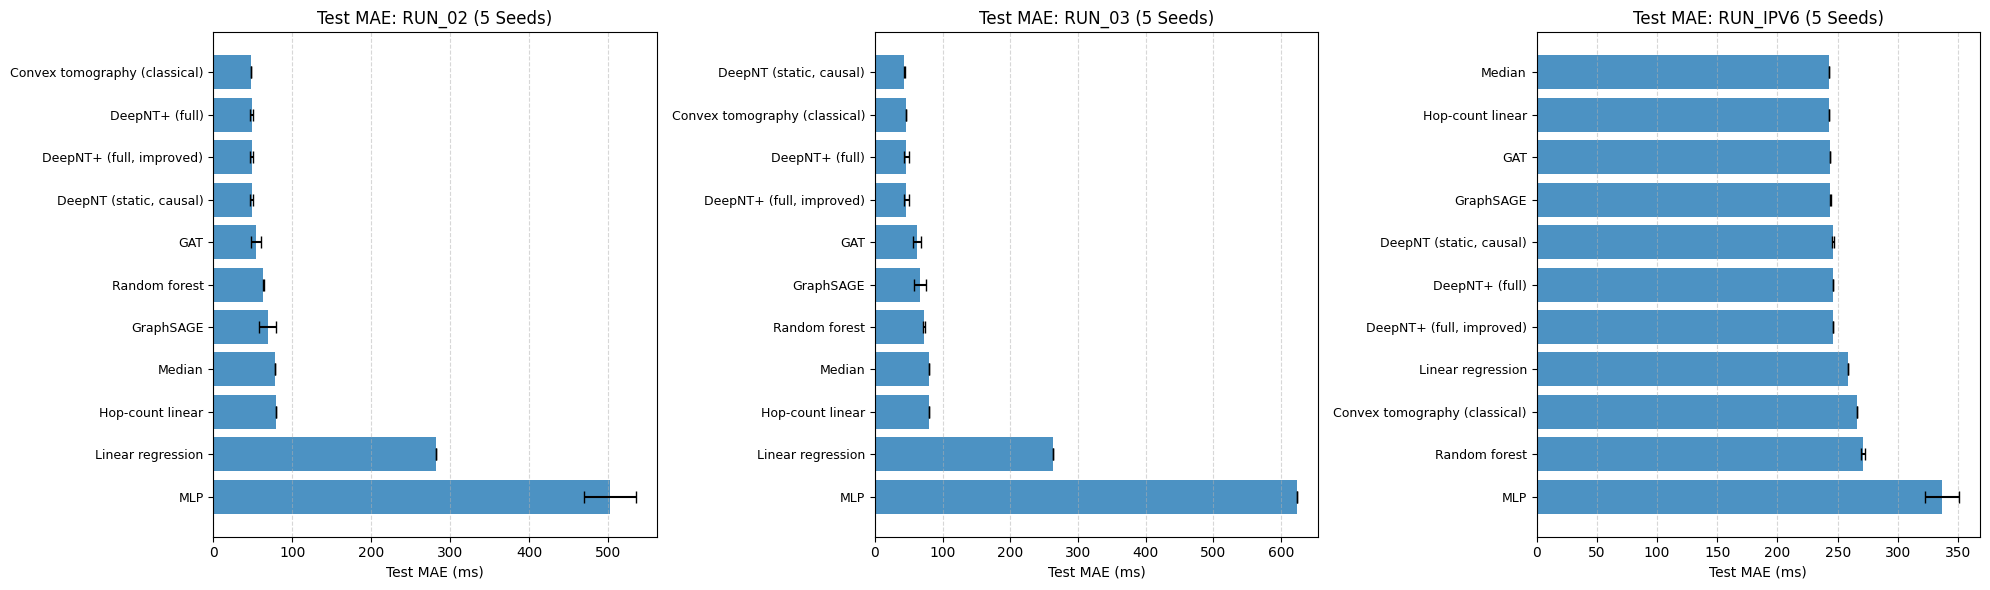

 Figure saved to: C:\Users\KINGDOM\Desktop\Thesis\DeepNT_Output\experiments\deepnt\benchmark_5seeds\master_benchmark_5seeds_chart.png


In [5]:
# ==============================================================================
# Cell 5: Publication-Quality Comparison Bar Charts
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (dname, _) in zip(axes, DATASETS.items()):
    d_csv = OUT_BASE / dname / 'metrics_summary.csv'
    if d_csv.exists():
        df = pd.read_csv(d_csv).sort_values('MAE_mean', ascending=False)
        y_pos = np.arange(len(df))
        ax.barh(y_pos, df['MAE_mean'], xerr=df['MAE_std'].fillna(0), color='tab:blue', alpha=0.8, capsize=4)
        ax.set_yticks(y_pos)
        ax.set_yticklabels(df['model'], fontsize=9)
        ax.set_xlabel('Test MAE (ms)')
        ax.set_title(f'Test MAE: {dname.upper()} (5 Seeds)')
        ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
fig_path = OUT_BASE / 'master_benchmark_5seeds_chart.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f" Figure saved to: {fig_path}")
